In [1]:
!pip install -q emoji emosent-py


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Shared code
Preprocessing and the model class live in one file. It gets copied into the artifacts folder so the offline demo imports *exactly* the same code.

In [5]:
%%writefile emoji_sentiment_lib.py
"""
emoji_sentiment_lib.py
Shared code for the Emoji-based Sentiment Classification project.
The training notebook writes this file into the artifacts folder, and the
offline demo notebook imports it from there, so preprocessing and the model
definition are guaranteed to be identical in both places.
"""
import os
import re
import json
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import emoji

LABELS = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}

_URL = re.compile(r"https?://\S+|www\.\S+")
_USER = re.compile(r"@\w+")
_WS = re.compile(r"\s+")
# skin-tone modifiers + variation selector -> stripped so 👍🏽 and 👍 share one embedding
_EMOJI_NOISE = re.compile("[\U0001F3FB-\U0001F3FF️]")


# ----------------------------------------------------------------------------
# Text preprocessing
# ----------------------------------------------------------------------------
def clean_text(text):
    """Replace links and @mentions with placeholders, squeeze whitespace."""
    text = _URL.sub("http", str(text))
    text = _USER.sub("@user", text)
    return _WS.sub(" ", text).strip()


def norm_emoji(e):
    """Canonical form of an emoji used as the vocabulary key."""
    out = _EMOJI_NOISE.sub("", e)
    return out if out else e


def extract_emojis(text):
    return [m["emoji"] for m in emoji.emoji_list(text)]


def has_emoji(text):
    return emoji.emoji_count(text) > 0


def _emoji_to_words(chars, data):
    name = (data or {}).get("en", ":emoji:")
    return " " + name.strip(":").replace("_", " ") + " "


def demojize_text(text):
    """'exam tomorrow 😭' -> 'exam tomorrow loudly crying face'"""
    return _WS.sub(" ", emoji.replace_emoji(text, replace=_emoji_to_words)).strip()


def emoji_only_text(text):
    """Keep only the emojis of a tweet: 'love this 😍🔥' -> '😍 🔥'"""
    return " ".join(extract_emojis(text))


def word_dropout(text, p, rng):
    """Randomly drop non-emoji words (training only) so the model learns to lean on emojis."""
    if p <= 0:
        return text
    toks = text.split()
    kept = [w for w in toks if has_emoji(w) or rng.random() >= p]
    return " ".join(kept) if kept else text


# ----------------------------------------------------------------------------
# Emoji vocabulary (+ lexicon prior from the Emoji Sentiment Ranking)
# ----------------------------------------------------------------------------
class EmojiVocab:
    PAD, UNK = 0, 1
    NEUTRAL_PRIOR = [1 / 3, 1 / 3, 1 / 3, 0.0]  # [p_neg, p_neu, p_pos, in_lexicon]

    def __init__(self, itos, prior):
        self.itos = list(itos)
        self.stoi = {e: i for i, e in enumerate(self.itos)}
        self.prior = np.asarray(prior, dtype=np.float32)

    def __len__(self):
        return len(self.itos)

    @classmethod
    def build(cls, lexicon_df, train_texts, min_count=1):
        itos = ["<pad>", "<unk>"]
        prior = [cls.NEUTRAL_PRIOR, cls.NEUTRAL_PRIOR]
        seen = set(itos)
        if lexicon_df is not None and len(lexicon_df):
            for row in lexicon_df.itertuples(index=False):
                key = norm_emoji(str(row.emoji))
                if key in seen:
                    continue
                seen.add(key)
                itos.append(key)
                prior.append([float(row.p_neg), float(row.p_neu), float(row.p_pos), 1.0])
        counts = Counter(norm_emoji(e) for t in train_texts for e in extract_emojis(t))
        for key, c in sorted(counts.items(), key=lambda kv: -kv[1]):
            if c >= min_count and key not in seen:
                seen.add(key)
                itos.append(key)
                prior.append(cls.NEUTRAL_PRIOR)
        return cls(itos, prior)

    def encode(self, text, max_emojis):
        ids = [self.stoi.get(norm_emoji(e), self.UNK) for e in extract_emojis(text)]
        return ids[:max_emojis]

    def save(self, path):
        with open(path, "w", encoding="utf-8") as f:
            json.dump({"itos": self.itos, "prior": self.prior.tolist()}, f, ensure_ascii=False)

    @classmethod
    def load(cls, path):
        with open(path, encoding="utf-8") as f:
            d = json.load(f)
        return cls(d["itos"], d["prior"])


# ----------------------------------------------------------------------------
# Batch builders
# ----------------------------------------------------------------------------
def prepare_plain_batch(tokenizer, texts, mode, max_len):
    """mode='raw' -> emojis kept as characters (setting B); mode='demoji' -> emojis as words (setting C)."""
    texts = [clean_text(t) for t in texts]
    if mode == "demoji":
        texts = [demojize_text(t) for t in texts]
    enc = tokenizer(texts, padding=True, truncation=True, max_length=max_len,
                    return_tensors="pt", return_token_type_ids=False)
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]}


def prepare_gated_batch(tokenizer, vocab, texts, max_len, max_emojis, word_drop=0.0, rng=None):
    """Inputs for the two-branch model: tokenised demojized text + emoji ids."""
    texts = [clean_text(t) for t in texts]
    text_in = [word_dropout(t, word_drop, rng) if (word_drop > 0 and rng is not None) else t for t in texts]
    text_in = [demojize_text(t) for t in text_in]
    enc = tokenizer(text_in, padding=True, truncation=True, max_length=max_len,
                    return_tensors="pt", return_token_type_ids=False)
    ids = [vocab.encode(t, max_emojis) for t in texts]
    width = max(1, max(len(x) for x in ids))
    emoji_ids = torch.zeros(len(ids), width, dtype=torch.long)
    emoji_mask = torch.zeros(len(ids), width, dtype=torch.float)
    for i, row in enumerate(ids):
        if row:
            emoji_ids[i, :len(row)] = torch.tensor(row)
            emoji_mask[i, :len(row)] = 1.0
    return {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"],
            "emoji_ids": emoji_ids, "emoji_mask": emoji_mask}


# ----------------------------------------------------------------------------
# text branch + emoji branch + trust gate
# ----------------------------------------------------------------------------
class GatedEmojiSentimentModel(nn.Module):
    def __init__(self, encoder, emoji_prior, n_labels=3, emoji_dim=64, hid=256, gate_bias_init=2.0):
        super().__init__()
        self.encoder = encoder
        H = getattr(encoder.config, "hidden_size", None) or getattr(encoder.config, "dim", 768)
        self.register_buffer("emoji_prior", torch.as_tensor(np.asarray(emoji_prior), dtype=torch.float32))
        n_emojis, prior_dim = self.emoji_prior.shape

        # emoji branch
        self.emoji_emb = nn.Embedding(n_emojis, emoji_dim, padding_idx=0)
        self.emoji_proj = nn.Sequential(nn.Linear(emoji_dim + prior_dim, hid), nn.GELU(), nn.Dropout(0.1))
        self.emoji_attn = nn.Linear(hid, 1)
        self.empty_emoji = nn.Parameter(torch.zeros(hid))

        # text branch
        self.text_proj = nn.Sequential(nn.Dropout(0.1), nn.Linear(H, hid), nn.GELU())

        # gate: starts at sigmoid(gate_bias_init) ~ 0.88 -> trusts emojis by default
        self.gate = nn.Linear(2 * hid, 1)
        nn.init.zeros_(self.gate.weight)
        nn.init.constant_(self.gate.bias, gate_bias_init)

        self.classifier = nn.Sequential(nn.Dropout(0.1), nn.Linear(hid, n_labels))
        self.emoji_head = nn.Linear(hid, n_labels)  # auxiliary head: emoji branch alone

    def forward(self, input_ids, attention_mask, emoji_ids, emoji_mask):
        h = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        t = self.text_proj(h)

        x = torch.cat([self.emoji_emb(emoji_ids), self.emoji_prior[emoji_ids]], dim=-1)
        x = self.emoji_proj(x)                                    # [B, E, hid]
        scores = self.emoji_attn(x).squeeze(-1).float()
        scores = scores.masked_fill(emoji_mask == 0, -1e4)
        attn = torch.softmax(scores, dim=-1) * emoji_mask         # zero for padding / no-emoji rows
        e = (attn.unsqueeze(-1).to(x.dtype) * x).sum(1)

        has = (emoji_mask.sum(1, keepdim=True) > 0).to(e.dtype)   # [B, 1]
        e = has * e + (1 - has) * self.empty_emoji.to(e.dtype)
        t = t.to(e.dtype)

        g = torch.sigmoid(self.gate(torch.cat([t, e], dim=-1))) * has
        fused = g * e + (1 - g) * t
        return {"logits": self.classifier(fused), "emoji_logits": self.emoji_head(e),
                "gate": g.squeeze(-1), "attn": attn, "has_emoji": has.squeeze(-1)}


def load_gated_model(model_dir, device="cpu"):
    from transformers import AutoConfig, AutoModel
    with open(os.path.join(model_dir, "gated_config.json")) as f:
        meta = json.load(f)
    vocab = EmojiVocab.load(os.path.join(model_dir, "emoji_vocab.json"))
    encoder = AutoModel.from_config(AutoConfig.from_pretrained(os.path.join(model_dir, "encoder_config")))
    model = GatedEmojiSentimentModel(encoder, vocab.prior, n_labels=len(LABELS), emoji_dim=meta["emoji_dim"],
                                     hid=meta["hid"], gate_bias_init=meta["gate_bias_init"])
    state = torch.load(os.path.join(model_dir, "model.pt"), map_location="cpu")
    model.load_state_dict(state)
    return model.to(device).eval(), vocab, meta


# ----------------------------------------------------------------------------
# Offline predictor used by the demo notebook
# ----------------------------------------------------------------------------
class SentimentPredictor:
    MODEL_NAMES = {"B": "B: DistilBERT (raw emojis)",
                   "C": "C: DistilBERT (demojized)",
                   "D": "D: Gated emoji model (ours)"}

    def __init__(self, art_dir, device=None, which=("B", "C", "D")):
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        mdir = os.path.join(art_dir, "models")
        self.tok = AutoTokenizer.from_pretrained(os.path.join(art_dir, "tokenizer"))
        self.models = {}
        if "B" in which:
            self.models["B"] = AutoModelForSequenceClassification.from_pretrained(
                os.path.join(mdir, "B_raw")).to(self.device).eval()
        if "C" in which:
            self.models["C"] = AutoModelForSequenceClassification.from_pretrained(
                os.path.join(mdir, "C_demoji")).to(self.device).eval()
        if "D" in which:
            self.models["D"], self.vocab, self.meta = load_gated_model(os.path.join(mdir, "D_gated"), self.device)
        self.max_len = getattr(self, "meta", {}).get("max_len", 128)
        self.max_emojis = getattr(self, "meta", {}).get("max_emojis", 8)

    @torch.no_grad()
    def predict(self, text):
        out = {}
        for key, mode in (("B", "raw"), ("C", "demoji")):
            if key in self.models:
                b = prepare_plain_batch(self.tok, [text], mode, self.max_len)
                b = {k: v.to(self.device) for k, v in b.items()}
                p = F.softmax(self.models[key](**b).logits.float(), -1)[0].cpu().numpy()
                out[key] = {"label": LABELS[int(p.argmax())], "probs": p}
        if "D" in self.models:
            b = prepare_gated_batch(self.tok, self.vocab, [text], self.max_len, self.max_emojis)
            b = {k: v.to(self.device) for k, v in b.items()}
            o = self.models["D"](**b)
            p = F.softmax(o["logits"].float(), -1)[0].cpu().numpy()
            ems = extract_emojis(clean_text(text))[: self.max_emojis]
            w = o["attn"][0, : len(ems)].float().cpu().numpy()
            out["D"] = {"label": LABELS[int(p.argmax())], "probs": p,
                        "gate": float(o["gate"][0]), "emoji_weights": list(zip(ems, w.tolist()))}
        return out

Overwriting emoji_sentiment_lib.py


In [9]:
import os, sys, json, time, random, shutil, subprocess, warnings, importlib
os.environ["TOKENIZERS_PARALLELISM"] = "false"
from collections import Counter
from functools import partial

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
import emoji
import transformers
from datasets import load_dataset, load_from_disk
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModel, get_linear_schedule_with_warmup

warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

sys.path.insert(0, os.getcwd())
import emoji_sentiment_lib as esl
importlib.reload(esl)

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.getcwd()
ART = os.path.join(WORK, "emoji_sentiment_artifacts")
for sub in ["data", "models", "figures", "wheels", "predictions"]:
    os.makedirs(os.path.join(ART, sub), exist_ok=True)
shutil.copy("emoji_sentiment_lib.py", os.path.join(ART, "emoji_sentiment_lib.py"))

CFG = dict(
    base_model="distilbert-base-uncased",
    max_len=128, max_emojis=8,
    batch_size=32, eval_batch_size=128, epochs=3,
    lr_bert=3e-5, lr_head=1e-3, weight_decay=0.01, warmup_ratio=0.06,
    # proposed-model settings
    emoji_dim=64, hid=256, gate_bias_init=2.0,   # sigmoid(2.0) ~ 0.88 -> leans on emojis at start
    aux_weight=0.3,                               # loss weight of the emoji-only auxiliary head
    emoji_only_aug_frac=1.0,                      # share of emoji tweets duplicated as emoji-only (all: they are scarce)
    word_dropout=0.15,                            # drop 15% of non-emoji words during training
    lexicon_min_occ=20, lexicon_min_conf=0.5,     # lexicon emojis added as tiny training examples
    seed=42, num_workers=2, force_retrain=False,
)
LABELS = esl.LABELS
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(CFG["seed"])

print("Device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| emoji", emoji.__version__)
print("Artifacts ->", ART)

Device: cpu 
torch 2.15.0+cpu | transformers 5.21.0 | emoji 2.16.0
Artifacts -> o:\studies sem 7\DL\project\v2\emoji_sentiment_artifacts


In [ ]:
# Cache the emoji wheel so the demo machine can install it with no internet
subprocess.run([sys.executable, "-m", "pip", "download", "-q", "--no-deps", "emoji", "-d", os.path.join(ART, "wheels")])
print(os.listdir(os.path.join(ART, "wheels")))

['emoji-2.16.0-py3-none-any.whl']


## 2. Data: TweetEval: Sentiment, re-split so emojis appear in training
Labels: 0 = negative, 1 = neutral, 2 = positive.


In [ ]:
from sklearn.model_selection import train_test_split
import glob

SPLIT_DIR = os.path.join(ART, "data", "splits")
DATA_DIR = os.path.join(ART, "data", "tweet_eval_sentiment")
if os.path.isdir(DATA_DIR):
    ds = load_from_disk(DATA_DIR)
    print("Loaded cached dataset")
else:
    try:
        ds = load_dataset("cardiffnlp/tweet_eval", "sentiment")
    except Exception as ex:
        print("cardiffnlp/tweet_eval failed, trying tweet_eval:", ex)
        ds = load_dataset("tweet_eval", "sentiment")
    ds.save_to_disk(DATA_DIR)

def prep(df, source):
    df = df[["text", "label"]].copy()
    df["text"] = df["text"].astype(str).map(esl.clean_text)
    df["label"] = df["label"].astype(int)
    df["source"] = source
    df["has_emoji"] = df["text"].map(esl.has_emoji)
    return df[df.text.str.len() > 0]

def split_50_10_40(df, seed):
    # stratify on label x has_emoji so every part gets its share of emoji tweets
    key = df["label"].astype(str) + "_" + df["has_emoji"].astype(str)
    tr, rest = train_test_split(df, train_size=0.5, stratify=key, random_state=seed)
    key_rest = rest["label"].astype(str) + "_" + rest["has_emoji"].astype(str)
    va, te = train_test_split(rest, train_size=0.2, stratify=key_rest, random_state=seed)  # 0.2 * 50% = 10%
    return tr, va, te



if os.path.exists(os.path.join(SPLIT_DIR, "train.csv")):
    train_df, val_df, test_df = (pd.read_csv(os.path.join(SPLIT_DIR, f"{s}.csv"), keep_default_na=False)
                                 for s in ["train", "val", "test"])
    print("Loaded cached splits from", SPLIT_DIR)
else:
    te_train = prep(ds["train"].to_pandas(), "tweeteval_train")
    te_val = prep(ds["validation"].to_pandas(), "tweeteval_val")
    s17_tr, s17_va, s17_te = split_50_10_40(prep(ds["test"].to_pandas(), "semeval2017"), CFG["seed"])
    parts_tr, parts_va, parts_te = [te_train, s17_tr], [te_val, s17_va], [s17_te]


    train_df, val_df, test_df = (pd.concat(p, ignore_index=True) for p in (parts_tr, parts_va, parts_te))
    os.makedirs(SPLIT_DIR, exist_ok=True)
    for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
        df.to_csv(os.path.join(SPLIT_DIR, f"{name}.csv"), index=False)

for df in (train_df, val_df, test_df):
    df["text"] = df["text"].astype(str)
    df["has_emoji"] = df["has_emoji"].astype(str).str.lower().isin(["true", "1"])

for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    dist = df["label"].value_counts(normalize=True).sort_index().round(3).tolist()
    print(f"{name:5s} n={len(df):6d} | emoji tweets: {df.has_emoji.sum():5d} ({df.has_emoji.mean():.1%}) "
          f"| label dist (neg,neu,pos): {dist}")
print("\nEmoji tweets per source (train):", train_df[train_df.has_emoji].source.value_counts().to_dict())
if train_df.has_emoji.sum() < 300:
    print("WARNING: very few emoji tweets in train - attach the airline dataset for more.")

n_show = min(5, int(train_df.has_emoji.sum()))
train_df[train_df.has_emoji].sample(n_show, random_state=0)[["text", "label", "source"]] if n_show else None

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

... (5 outputs left out)

Saving the dataset (0/1 shards):   0%|          | 0/12284 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2000 [00:00<?, ? examples/s]

Airline dataset not attached (optional) -> using TweetEval / SemEval-2017 only
train n= 51757 | emoji tweets:   405 (0.8%) | label dist (neg,neu,pos): [0.175, 0.457, 0.368]
val   n=  3228 | emoji tweets:    81 (2.5%) | label dist (neg,neu,pos): [0.22, 0.453, 0.327]
test  n=  4914 | emoji tweets:   323 (6.6%) | label dist (neg,neu,pos): [0.323, 0.483, 0.193]

Emoji tweets per source (train): {'semeval2017': 405}


,text,label,source
51711,Niggas be broke that's the reason they hate fl...,0,semeval2017
49241,"That's incorrect I do, no one gets to clock ou...",1,semeval2017
46557,That's beautiful ❤ #BeautyAndTheBeast,2,semeval2017
49079,Can't wait till Christmas and valentines day😊,2,semeval2017
47580,When i was in the 11th. I went to get this gir...,1,semeval2017


## 3. Emoji Sentiment Ranking lexicon
Kralj Novak et al. (2015), *Sentiment of Emojis* : 751 emojis with counts of negative / neutral / positive tweets.
These scores become each emoji's **prior** in the emoji branch.

In [ ]:
LEX_PATH = os.path.join(ART, "data", "emoji_sentiment_lexicon.csv")
LEX_COLS = ["emoji", "neg", "neu", "pos"]

def lex_from_clarin():
    url = "https://www.clarin.si/repository/xmlui/bitstream/handle/11356/1048/Emoji_Sentiment_Data_v1.0.csv"
    raw = pd.read_csv(url)
    return pd.DataFrame({"emoji": raw.iloc[:, 0].astype(str), "neg": raw.iloc[:, 4],
                         "neu": raw.iloc[:, 5], "pos": raw.iloc[:, 6]})

def lex_from_emosent():
    from emosent import get_emoji_sentiment_rank
    rows, seen = [], set()
    for e in list(emoji.EMOJI_DATA):
        for cand in (e, esl.norm_emoji(e)):
            if cand in seen:
                continue
            try:
                r = get_emoji_sentiment_rank(cand)
            except Exception:
                r = None
            if r:
                seen.add(cand)
                rows.append({"emoji": cand, "neg": r["negative"], "neu": r["neutral"], "pos": r["positive"]})
                break
    return pd.DataFrame(rows)

if os.path.exists(LEX_PATH):
    lex = pd.read_csv(LEX_PATH)
    print("Loaded cached lexicon")
else:
    lex = None
    for src, fn in [("CLARIN", lex_from_clarin), ("emosent-py", lex_from_emosent)]:
        try:
            lex = fn()
            if len(lex) > 100 and lex["emoji"].astype(str).map(esl.has_emoji).mean() > 0.8:
                print(f"Lexicon from {src}: {len(lex)} emojis")
                break
        except Exception as ex:
            print(f"{src} failed: {ex}")
            lex = None
        else:
            lex = None
    if lex is None or len(lex) == 0:
        print("WARNING: no lexicon available -> emoji priors will be neutral (model still trains).")
        lex = pd.DataFrame(columns=LEX_COLS)
    tot = lex[["neg", "neu", "pos"]].sum(1).astype(float)
    for c in ["neg", "neu", "pos"]:
        lex["p_" + c] = (lex[c].astype(float) + 1) / (tot + 3)          # Laplace smoothing
    lex["total"] = tot
    lex["score"] = lex["p_pos"] - lex["p_neg"]
    lex.to_csv(LEX_PATH, index=False)

if len(lex):
    top = lex[lex.total >= 50].sort_values("score")
    print("Most negative:", " ".join(top.emoji.head(10)))
    print("Most positive:", " ".join(top.emoji.tail(10)))

Lexicon from emosent-py: 736 emojis
Most negative: 👿 ✂ 🚫 😕 😐 😒 😿 😦 😩 😑
Most positive: 💙 💃 💐 🎉 💞 ❤ 🎁 😙 🌼 🎎


In [ ]:
vocab = esl.EmojiVocab.build(lex, train_df["text"])
occ = Counter(esl.norm_emoji(e) for t in train_df.text for e in esl.extract_emojis(t))
in_lex = sum(c for e, c in occ.items() if vocab.prior[vocab.stoi[e], 3] == 1.0)
print(f"Emoji vocab size: {len(vocab)} | unique emojis in train: {len(occ)} | "
      f"train emoji occurrences covered by lexicon: {in_lex / max(1, sum(occ.values())):.1%}")
print("Most common emojis in train:", " ".join(e for e, _ in occ.most_common(20)))

Emoji vocab size: 761 | unique emojis in train: 200 | train emoji occurrences covered by lexicon: 90.3%
Most common emojis in train: 😂 😍 ❤ 😭 🙄 💙 👍 👏 👌 😎 🤔 🏃 😊 😩 💋 😢 🇺🇸 😁 🙏 😱


## 4. Why emojis need special handling
How many emoji occurrences does the DistilBERT tokenizer turn into `[UNK]`? Whatever is lost here is lost to setting **B**.

In [ ]:
tok = AutoTokenizer.from_pretrained(CFG["base_model"])
tok.save_pretrained(os.path.join(ART, "tokenizer"))

unk_occ = sum(c for e, c in occ.items() if tok.unk_token_id in tok(e, add_special_tokens=False)["input_ids"])
print(f"Emoji occurrences mapped to [UNK] by the tokenizer: {unk_occ / max(1, sum(occ.values())):.1%}")
for s in ["exam tomorrow 😭😭", "love this 😍🔥"]:
    print(f"\n{s}\n  raw     -> {tok.tokenize(s)}\n  demoji  -> {tok.tokenize(esl.demojize_text(s))}")

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: GET https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/tokenizer_config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: GET https://huggingface.co/distilbert-base-uncased/resolve/main/tokenizer_config.json "HTTP/1.1 200 OK"


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

48 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 307 Temporary Redirect"
48 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
48 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 307 Temporary Redirect"
48 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/vocab.txt "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: GET https://huggingface.co/distilbert-base-uncased/resolve/main/vocab.txt "HTTP/1.1 200 OK"


vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/tokenizer.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: GET https://huggingface.co/distilbert-base-uncased/resolve/main/tokenizer.json "HTTP/1.1 200 OK"


tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/added_tokens.json "HTTP/1.1 404 Not Found"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/special_tokens_map.json "HTTP/1.1 404 Not Found"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/chat_template.jinja "HTTP/1.1 404 Not Found"


Emoji occurrences mapped to [UNK] by the tokenizer: 99.1%

exam tomorrow 😭😭
  raw     -> ['exam', 'tomorrow', '[UNK]']
  demoji  -> ['exam', 'tomorrow', 'loudly', 'crying', 'face', 'loudly', 'crying', 'face']

love this 😍🔥
  raw     -> ['love', 'this', '[UNK]']
  demoji  -> ['love', 'this', 'smiling', 'face', 'with', 'heart', '-', 'eyes', 'fire']


## 5. Extra training data for final proposed model
1. **Original tweets.**
2. **Emoji-only copies:** for every emoji tweet, add a copy with only the emojis (same label), so it works when the input is just emojis.
3. **Lexicon examples:** each frequent, clearly-polarised lexicon emoji becomes a one-emoji example (😍 → positive).

(Word dropout is applied on the fly in the data loader.) Baselines B and C are trained on the original tweets only.

In [ ]:
rng = random.Random(CFG["seed"])
rows = [(t, int(l), "original") for t, l in zip(train_df.text, train_df.label)]
for t, l in zip(train_df.text[train_df.has_emoji], train_df.label[train_df.has_emoji]):
    if rng.random() < CFG["emoji_only_aug_frac"]:
        rows.append((esl.emoji_only_text(t), int(l), "emoji_only_aug"))
for r in lex.itertuples(index=False):
    probs = np.array([r.p_neg, r.p_neu, r.p_pos])
    if r.total >= CFG["lexicon_min_occ"] and probs.max() >= CFG["lexicon_min_conf"] and esl.has_emoji(str(r.emoji)):
        rows.append((str(r.emoji), int(probs.argmax()), "lexicon"))
d_train_df = pd.DataFrame(rows, columns=["text", "label", "kind"])
print(d_train_df.kind.value_counts())

kind
original          51757
emoji_only_aug      405
lexicon             269
Name: count, dtype: int64


## 6. Data loaders and training utilities

In [ ]:
class TextDS(Dataset):
    def __init__(self, df):
        self.t, self.l = df["text"].tolist(), df["label"].astype(int).tolist()
    def __len__(self): return len(self.t)
    def __getitem__(self, i): return self.t[i], self.l[i]

def plain_collate(batch, mode):
    texts, labels = zip(*batch)
    b = esl.prepare_plain_batch(tok, list(texts), mode, CFG["max_len"])
    b["labels"] = torch.tensor(labels)
    return b

_drop_rng = random.Random(CFG["seed"] + 1)
def gated_collate(batch, train):
    texts, labels = zip(*batch)
    b = esl.prepare_gated_batch(tok, vocab, list(texts), CFG["max_len"], CFG["max_emojis"],
                                word_drop=CFG["word_dropout"] if train else 0.0, rng=_drop_rng if train else None)
    b["labels"] = torch.tensor(labels)
    return b

def make_loader(df, kind, train, mode=None):
    collate = partial(plain_collate, mode=mode) if kind == "plain" else partial(gated_collate, train=train)
    return DataLoader(TextDS(df), batch_size=CFG["batch_size"] if train else CFG["eval_batch_size"],
                      shuffle=train, collate_fn=collate, num_workers=CFG["num_workers"])

def forward(model, batch, kind):
    if kind == "plain":
        return {"logits": model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits}
    return model(batch["input_ids"], batch["attention_mask"], batch["emoji_ids"], batch["emoji_mask"])

def compute_loss(out, labels, kind):
    loss = F.cross_entropy(out["logits"].float(), labels)
    if kind == "gated":
        has = out["has_emoji"] > 0
        if has.any():
            loss = loss + CFG["aux_weight"] * F.cross_entropy(out["emoji_logits"][has].float(), labels[has])
    return loss

def metrics(y, p):
    return {"accuracy": accuracy_score(y, p), "macro_f1": f1_score(y, p, average="macro"),
            "macro_recall": recall_score(y, p, average="macro")}  # macro-recall = official TweetEval metric

@torch.no_grad()
def predict_loader(model, loader, kind):
    model.eval()
    P, G, Y = [], [], []
    for batch in loader:
        Y.append(batch.pop("labels"))
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            out = forward(model, batch, kind)
        P.append(F.softmax(out["logits"].float(), -1).cpu())
        if kind == "gated":
            G.append(out["gate"].float().cpu())
    probs = torch.cat(P).numpy()
    return probs, torch.cat(Y).numpy(), (torch.cat(G).numpy() if G else None)

def train_model(model, kind, train_loader, val_loader, param_groups, tag):
    steps = len(train_loader) * CFG["epochs"]
    opt = torch.optim.AdamW(param_groups, weight_decay=CFG["weight_decay"])
    sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup_ratio"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best_f1, best_state, history = -1, None, []
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); t0, run = time.time(), 0.0
        for i, batch in enumerate(train_loader, 1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                loss = compute_loss(forward(model, batch, kind), labels, kind)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item()
            if i % 300 == 0:
                print(f"  [{tag}] epoch {ep} step {i}/{len(train_loader)} loss {run / i:.4f}")
        probs, y, _ = predict_loader(model, val_loader, kind)
        m = metrics(y, probs.argmax(1)); m.update(epoch=ep, train_loss=run / len(train_loader), minutes=(time.time() - t0) / 60)
        history.append(m)
        print(f"[{tag}] epoch {ep}: val acc {m['accuracy']:.4f} | macro-F1 {m['macro_f1']:.4f} | {m['minutes']:.1f} min")
        if m["macro_f1"] > best_f1:
            best_f1 = m["macro_f1"]
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print(f"[{tag}] best val macro-F1 {best_f1:.4f}")
    return history

def is_done(d): return os.path.exists(os.path.join(d, "DONE"))
def mark_done(d, history):
    json.dump(history, open(os.path.join(d, "history.json"), "w"), indent=2)
    open(os.path.join(d, "DONE"), "w").write(time.ctime())

## 7. Baselines B (raw emojis) and C (demojized)

In [ ]:
def train_or_load_plain(tag, mode):
    out_dir = os.path.join(ART, "models", tag)
    if is_done(out_dir) and not CFG["force_retrain"]:
        print(f"{tag}: found saved weights -> loading, not retraining")
        return AutoModelForSequenceClassification.from_pretrained(out_dir).to(DEVICE)
    set_seed(CFG["seed"])
    model = AutoModelForSequenceClassification.from_pretrained(
        CFG["base_model"], num_labels=3, id2label=dict(enumerate(LABELS)), label2id=esl.LABEL2ID).to(DEVICE)
    hist = train_model(model, "plain", make_loader(train_df, "plain", True, mode),
                       make_loader(val_df, "plain", False, mode),
                       [{"params": model.parameters(), "lr": CFG["lr_bert"]}], tag)
    os.makedirs(out_dir, exist_ok=True)
    model.save_pretrained(out_dir); tok.save_pretrained(out_dir)
    mark_done(out_dir, hist)
    return model

model_B = train_or_load_plain("B_raw", "raw")

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/model.safetensors "HTTP/1.1 302 Found"
48 | INFO | HTTP Request: GET https://huggingface.co/api/models/distilbert/distilbert-base-uncased/xet-read-token/12040accade4e8a0f71eabdb258fecc2e7e948be "HTTP/1.1 200 OK"


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

  [B_raw] epoch 1 step 300/1618 loss 0.8634
  [B_raw] epoch 1 step 600/1618 loss 0.7779
  [B_raw] epoch 1 step 900/1618 loss 0.7373
  [B_raw] epoch 1 step 1200/1618 loss 0.7141
  [B_raw] epoch 1 step 1500/1618 loss 0.6976
[B_raw] epoch 1: val acc 0.7237 | macro-F1 0.7242 | 1.7 min
  [B_raw] epoch 2 step 300/1618 loss 0.5003
  [B_raw] epoch 2 step 600/1618 loss 0.4979
  [B_raw] epoch 2 step 900/1618 loss 0.4937
  [B_raw] epoch 2 step 1200/1618 loss 0.4944
  [B_raw] epoch 2 step 1500/1618 loss 0.4971
[B_raw] epoch 2: val acc 0.7277 | macro-F1 0.7281 | 1.7 min
  [B_raw] epoch 3 step 300/1618 loss 0.3611
  [B_raw] epoch 3 step 600/1618 loss 0.3540
  [B_raw] epoch 3 step 900/1618 loss 0.3547
  [B_raw] epoch 3 step 1200/1618 loss 0.3511
  [B_raw] epoch 3 step 1500/1618 loss 0.3517
[B_raw] epoch 3: val acc 0.7265 | macro-F1 0.7256 | 1.7 min
[B_raw] best val macro-F1 0.7281


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
model_C = train_or_load_plain("C_demoji", "demoji")

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

  [C_demoji] epoch 1 step 300/1618 loss 0.8669
  [C_demoji] epoch 1 step 600/1618 loss 0.7775
  [C_demoji] epoch 1 step 900/1618 loss 0.7393
  [C_demoji] epoch 1 step 1200/1618 loss 0.7154
  [C_demoji] epoch 1 step 1500/1618 loss 0.6989
[C_demoji] epoch 1: val acc 0.7302 | macro-F1 0.7292 | 1.7 min
  [C_demoji] epoch 2 step 300/1618 loss 0.4996
  [C_demoji] epoch 2 step 600/1618 loss 0.4988
  [C_demoji] epoch 2 step 900/1618 loss 0.4933
  [C_demoji] epoch 2 step 1200/1618 loss 0.4953
  [C_demoji] epoch 2 step 1500/1618 loss 0.4969
[C_demoji] epoch 2: val acc 0.7246 | macro-F1 0.7254 | 1.7 min
  [C_demoji] epoch 3 step 300/1618 loss 0.3572
  [C_demoji] epoch 3 step 600/1618 loss 0.3504
  [C_demoji] epoch 3 step 900/1618 loss 0.3534
  [C_demoji] epoch 3 step 1200/1618 loss 0.3507
  [C_demoji] epoch 3 step 1500/1618 loss 0.3505
[C_demoji] epoch 3: val acc 0.7292 | macro-F1 0.7282 | 1.7 min
[C_demoji] best val macro-F1 0.7292


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## 8. model D: text branch + emoji branch + trust gate

In [ ]:
D_DIR = os.path.join(ART, "models", "D_gated")
if is_done(D_DIR) and not CFG["force_retrain"]:
    print("D_gated: found saved weights -> loading, not retraining")
    model_D, vocab, _ = esl.load_gated_model(D_DIR, DEVICE)
else:
    set_seed(CFG["seed"])
    encoder = AutoModel.from_pretrained(CFG["base_model"])
    model_D = esl.GatedEmojiSentimentModel(encoder, vocab.prior, n_labels=3, emoji_dim=CFG["emoji_dim"],
                                           hid=CFG["hid"], gate_bias_init=CFG["gate_bias_init"]).to(DEVICE)
    enc_params = list(model_D.encoder.parameters())
    enc_ids = {id(p) for p in enc_params}
    head_params = [p for p in model_D.parameters() if id(p) not in enc_ids]
    print(f"Encoder params: {sum(p.numel() for p in enc_params)/1e6:.1f}M | "
          f"emoji branch + gate + heads: {sum(p.numel() for p in head_params)/1e6:.2f}M")
    hist = train_model(model_D, "gated", make_loader(d_train_df, "gated", True), make_loader(val_df, "gated", False),
                       [{"params": enc_params, "lr": CFG["lr_bert"]}, {"params": head_params, "lr": CFG["lr_head"]}],
                       "D_gated")
    os.makedirs(D_DIR, exist_ok=True)
    torch.save(model_D.state_dict(), os.path.join(D_DIR, "model.pt"))
    model_D.encoder.config.save_pretrained(os.path.join(D_DIR, "encoder_config"))
    vocab.save(os.path.join(D_DIR, "emoji_vocab.json"))
    json.dump({k: CFG[k] for k in ["emoji_dim", "hid", "gate_bias_init", "max_len", "max_emojis", "base_model"]},
              open(os.path.join(D_DIR, "gated_config.json"), "w"), indent=2)
    tok.save_pretrained(D_DIR)
    mark_done(D_DIR, hist)

48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"
48 | INFO | HTTP Request: HEAD https://huggingface.co/distilbert-base-uncased/resolve/main/config.json "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

Encoder params: 66.4M | emoji branch + gate + heads: 0.27M
  [D_gated] epoch 1 step 300/1639 loss 0.9959
  [D_gated] epoch 1 step 600/1639 loss 0.9465
  [D_gated] epoch 1 step 900/1639 loss 0.9166
  [D_gated] epoch 1 step 1200/1639 loss 0.9015
  [D_gated] epoch 1 step 1500/1639 loss 0.8873
[D_gated] epoch 1: val acc 0.7153 | macro-F1 0.7158 | 1.8 min
  [D_gated] epoch 2 step 300/1639 loss 0.7268
  [D_gated] epoch 2 step 600/1639 loss 0.7304
  [D_gated] epoch 2 step 900/1639 loss 0.7282
  [D_gated] epoch 2 step 1200/1639 loss 0.7239
  [D_gated] epoch 2 step 1500/1639 loss 0.7186
[D_gated] epoch 2: val acc 0.7296 | macro-F1 0.7248 | 1.7 min
  [D_gated] epoch 3 step 300/1639 loss 0.6391
  [D_gated] epoch 3 step 600/1639 loss 0.6404
  [D_gated] epoch 3 step 900/1639 loss 0.6328
  [D_gated] epoch 3 step 1200/1639 loss 0.6297
  [D_gated] epoch 3 step 1500/1639 loss 0.6283
[D_gated] epoch 3: val acc 0.7333 | macro-F1 0.7323 | 1.7 min
[D_gated] best val macro-F1 0.7323


## 9. Evaluation on three test sets
* **full_test** – our held-out test set (40% of SemEval-2017, plus 40% of the airline data if attached)
* **emoji_tweets** – only test tweets that contain at least one emoji
* **emoji_only** – the same emoji tweets with all words removed (labels kept). This is a stress test: the original label sometimes depends on the words (e.g. sarcasm), so no model can be perfect here.

In [ ]:
test_emoji = test_df[test_df.has_emoji].reset_index(drop=True)
test_emoji_only = test_emoji.assign(text=test_emoji.text.map(esl.emoji_only_text))
EVAL_SETS = {"full_test": test_df.reset_index(drop=True), "emoji_tweets": test_emoji, "emoji_only": test_emoji_only}
MODELS = {"B_raw": (model_B, "plain", "raw"), "C_demoji": (model_C, "plain", "demoji"), "D_gated": (model_D, "gated", None)}

results, gates = [], {}
for set_name, df in EVAL_SETS.items():
    pred_df = df[["text", "label"]].copy()
    for m_name, (model, kind, mode) in MODELS.items():
        probs, y, g = predict_loader(model, make_loader(df, kind, False, mode), kind)
        pred_df[m_name] = probs.argmax(1)
        pred_df[m_name + "_conf"] = probs.max(1).round(4)
        if g is not None:
            pred_df["D_gate"] = g.round(4); gates[set_name] = g
        results.append({"eval_set": set_name, "model": m_name, "n": len(df), **metrics(y, probs.argmax(1))})
    pred_df.to_csv(os.path.join(ART, "predictions", f"{set_name}.csv"), index=False)

res = pd.DataFrame(results)
res.to_csv(os.path.join(ART, "results.csv"), index=False)
res.pivot(index="model", columns="eval_set", values="macro_f1").round(4)[list(EVAL_SETS)]

eval_set,full_test,emoji_tweets,emoji_only
model,,,
B_raw,0.7093,0.6812,0.1647
C_demoji,0.7179,0.7008,0.4605
D_gated,0.7198,0.7128,0.5018


In [ ]:
res.pivot(index="model", columns="eval_set", values="accuracy").round(4)[list(EVAL_SETS)]

eval_set,full_test,emoji_tweets,emoji_only
model,,,
B_raw,0.7082,0.6966,0.3282
C_demoji,0.7177,0.7214,0.5015
D_gated,0.7210,0.7368,0.5604


## 10. Figures (saved to `figures/`)

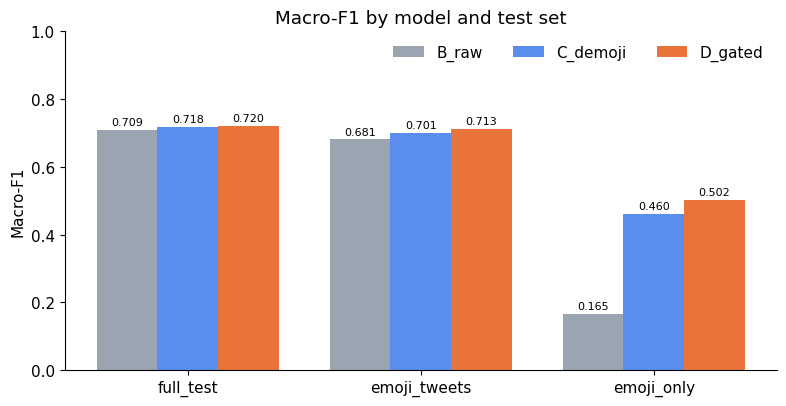

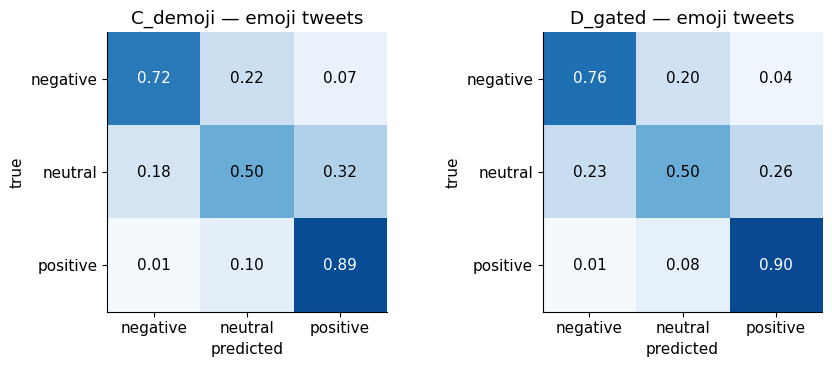

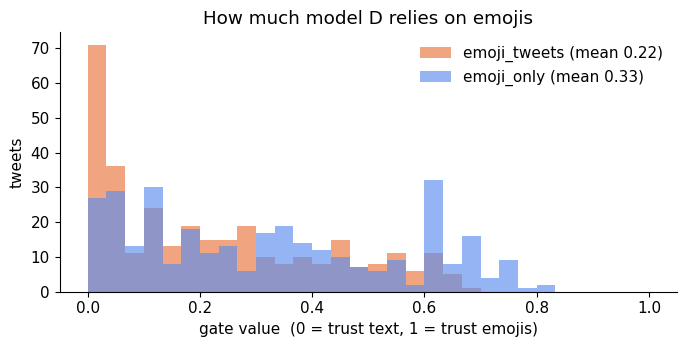

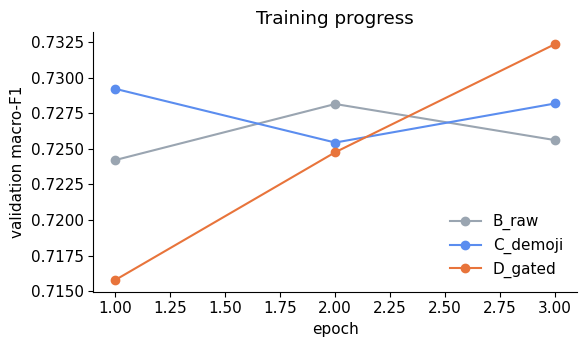

In [ ]:
FIG = os.path.join(ART, "figures")
COLORS = {"B_raw": "#9aa5b1", "C_demoji": "#5b8def", "D_gated": "#e8743b"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

# (a) macro-F1 comparison
fig, ax = plt.subplots(figsize=(8, 4.2))
sets, w = list(EVAL_SETS), 0.26
for i, m in enumerate(MODELS):
    vals = [res[(res.model == m) & (res.eval_set == s)].macro_f1.item() for s in sets]
    bars = ax.bar(np.arange(len(sets)) + (i - 1) * w, vals, w, label=m, color=COLORS[m])
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(range(len(sets)), sets); ax.set_ylabel("Macro-F1"); ax.set_ylim(0, 1)
ax.set_title("Macro-F1 by model and test set"); ax.legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "macro_f1_comparison.png"), dpi=150); plt.show()

# (b) confusion matrices C vs D on emoji tweets
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
pe = pd.read_csv(os.path.join(ART, "predictions", "emoji_tweets.csv"))
for ax, m in zip(axes, ["C_demoji", "D_gated"]):
    cm = confusion_matrix(pe.label, pe[m], labels=[0, 1, 2], normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "black")
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{m} — emoji tweets")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "confusion_emoji_tweets.png"), dpi=150); plt.show()



# (d) validation curves
fig, ax = plt.subplots(figsize=(6, 3.6))
for m in MODELS:
    h = json.load(open(os.path.join(ART, "models", m, "history.json")))
    ax.plot([x["epoch"] for x in h], [x["macro_f1"] for x in h], marker="o", label=m, color=COLORS[m])
ax.set_xlabel("epoch"); ax.set_ylabel("validation macro-F1"); ax.set_title("Training progress"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "val_curves.png"), dpi=150); plt.show()

## 11. When does D trust the text over the emojis?
Lowest-gate emoji tweets = cases where the words override the emoji (often sarcasm or mixed feelings).

In [ ]:
pe["true"] = pe.label.map(dict(enumerate(LABELS))); pe["D_pred"] = pe.D_gated.map(dict(enumerate(LABELS)))
pd.set_option("display.max_colwidth", 120)
print("Trusts TEXT most:"); display(pe.nsmallest(8, "D_gate")[["text", "true", "D_pred", "D_gate"]])
print("Trusts EMOJIS most:"); display(pe.nlargest(8, "D_gate")[["text", "true", "D_pred", "D_gate"]])
fixed = pe[(pe.D_gated == pe.label) & (pe.C_demoji != pe.label)]
print(f"Emoji tweets D gets right but C gets wrong: {len(fixed)}  |  the reverse: "
      f"{len(pe[(pe.C_demoji == pe.label) & (pe.D_gated != pe.label)])}")
display(fixed.head(8)[["text", "true", "D_pred", "D_gate"]])

Trusts TEXT most:


,text,true,D_pred,D_gate
269,Loser in Chief 😡#trumptransitionteam #notmypresident #fucktrump #jewishresistance…,negative,negative,0.0011
28,Reckless Moron. 😡🌪🇺🇸#trumptransitionteam #notmypresident #fucktrump #jewishresistance…,negative,negative,0.0013
232,@user AMAZES ME THAT MORONS WHO CLAIM THEY R RIGHT WING CONSERVATIVE CAN ONLY SPEW VENOM NEVER A SOLUTION 2ANY PROBL...,negative,negative,0.0021
71,America's Nightmare. 🇺🇸😱💤#trumptransitionteam #notmypresident #fucktrump #nohateinwhitehouse…,negative,negative,0.0024
31,#GilmoreGirlsTop4 1.Sukie2.Luke3.Kurk4.Jess I can't wait for the new series to start! 😍✨🎉,positive,positive,0.0032
57,Finally time to see #FantasticBeasts! Going with my dad cuz he loves #HarryPotter magic too and is the only series h...,positive,positive,0.0033
162,@user @user @user losing their cool because the refs are one sided. 😡,negative,negative,0.0042
211,working on the New Years & Valentines collection.😍 this is lit cant wait to reveal,positive,positive,0.0047


Trusts EMOJIS most:


,text,true,D_pred,D_gate
2,"Natalie Cole, #Bowie, #Prince, Leonard Cohen, Leon Russell, Gwen Ifill, #SharonJones, & now #FidelCastro? Geez, 2016. 😭",negative,neutral,0.6777
276,"@user #Venezuelan 😷President Nicolas Maduro called Cuban Raul, expresses solidarity with Cuban ppl following death o...",neutral,neutral,0.6646
81,"📷 becausemessi: According to Deportes Cuatro, Lionel Messi and Cristiano Ronaldo found a moment to...",neutral,positive,0.6548
236,@user Go get em girl!!!! 👊🏽,positive,positive,0.6533
225,Who's better than Grayson Allen or josh Jackson 😂😂😂😂😂,neutral,neutral,0.6479
262,I'm officially giving up the #Hatchimals hunt now I mean it this time 😂,neutral,neutral,0.6353
4,Comeee onnnnn kim jong un😭😭😭😭,negative,neutral,0.6304
43,Mannequin Challenge Part 2. Peep me being fat with the whipped cream 😂 #mannequinchallenge,neutral,neutral,0.6245


Emoji tweets D gets right but C gets wrong: 30  |  the reverse: 25


,text,true,D_pred,D_gate
13,I FORGOT HIS TAIL 😂 #BeautyAndTheBeast,neutral,neutral,0.6235
25,When your friends come back from college for thanksgiving break😬😂😂 @user @user @user,neutral,neutral,0.5767
43,Mannequin Challenge Part 2. Peep me being fat with the whipped cream 😂 #mannequinchallenge,neutral,neutral,0.6245
46,New tumblr post: @user New tumblr post: @user @user yo! Hot #uber driver last night 😝 #T…,positive,positive,0.6084
52,@user from @user - 🍑Shake your Bon-bon 🍑 @user #rickymartin #onewor…,positive,positive,0.3279
73,This week; Scouts are working towards their next level of emergency aid badge & both Cubs & Beavers are making Chris...,positive,positive,0.2410
79,can you roll up to my house with roses on valentines? 🤔🌹 @user,positive,positive,0.2172
93,"""If you are traveling with the samsung galaxy note 7, please leave it at the service desk and we will be happy to th...",neutral,neutral,0.5991


In [ ]:
del MODELS, model_B, model_C, model_D
torch.cuda.empty_cache()
predictor = esl.SentimentPredictor(ART)
for s in ["exam tomorrow 😭😭", "😡😡😡", "😍🔥", "great, another monday 🙂", "the bus was late again", "🤔"]:
    r = predictor.predict(s)
    print(f"{s:30s} B={r['B']['label']:8s} C={r['C']['label']:8s} D={r['D']['label']:8s} gate={r['D']['gate']:.2f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

exam tomorrow 😭😭               B=neutral  C=negative D=neutral  gate=0.63
😡😡😡                            B=neutral  C=negative D=negative gate=0.01
😍🔥                             B=neutral  C=positive D=positive gate=0.04
great, another monday 🙂        B=positive C=positive D=positive gate=0.10
the bus was late again         B=negative C=neutral  D=negative gate=0.00
🤔                              B=neutral  C=neutral  D=neutral  gate=0.39


## 13. Package everything

In [ ]:
def dir_size(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs)

manifest = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "config": CFG,
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__,
                 "emoji": emoji.__version__, "python": sys.version.split()[0]},
    "results": results,
    "size_mb": round(dir_size(ART) / 1e6, 1),
}
json.dump(manifest, open(os.path.join(ART, "manifest.json"), "w"), indent=2, default=str)

shutil.make_archive(os.path.join(WORK, "emoji_sentiment_artifacts"), "zip", ART)
print(f"Artifacts folder: {manifest['size_mb']} MB")
print("Zip:", os.path.join(WORK, "emoji_sentiment_artifacts.zip"),
      f"({os.path.getsize(os.path.join(WORK, 'emoji_sentiment_artifacts.zip')) / 1e6:.0f} MB)")
for r, _, fs in os.walk(ART):
    depth = r[len(ART):].count(os.sep)
    if depth <= 2:
        print("  " * depth + os.path.basename(r) + "/", f"({len(fs)} files)")

Artifacts folder: 821.4 MB
Zip: /kaggle/working/emoji_sentiment_artifacts.zip (748 MB)
emoji_sentiment_artifacts/ (3 files)
  predictions/ (3 files)
  wheels/ (1 files)
  data/ (1 files)
    splits/ (3 files)
    tweet_eval_sentiment/ (1 files)
  tokenizer/ (2 files)
  figures/ (4 files)
  models/ (0 files)
    B_raw/ (6 files)
    C_demoji/ (6 files)
    D_gated/ (7 files)
